# Which ZIPs already host a data center, and which ones are next?

Merascope's public risk page (`merascope.com/#/risk`) ranks every one of the 33,252
ZCTAs in the contiguous US into 10 tiers by how much its own siting model thinks the
ZIP resembles places that already host a data center. Each tier carries two real
observed rates over the *same* set of ZIPs: the share that already host a facility,
and the share with something proposed or permitted but not yet built.

This notebook recomputes those numbers from the model table directly (not typed in
by hand), cross-checks them against the live `/api/risk/tiers` endpoint, and builds
the two charts for the post.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request

sys.path.insert(0, str(Path("../../merascope/notebooks").resolve()))
import dcmodel as D

df = D.load_model_table()
print(f"{len(df)} ZCTAs loaded")

33252 ZCTAs loaded


## Tier shares of the national total

The live page reports observed *rate* per tier (what fraction of that tier's ZIPs
host a facility). For the chart, what matters is each tier's *share of the national
total* -- built and pipeline plotted on the same 0-100% scale, which the raw rates
can't do (built rates span 0.12%-15.4%, pipeline rates span 0.00%-2.2% -- a shared
linear axis would flatten the pipeline series to invisible).

In [2]:
tiers_live = json.loads(urllib.request.urlopen("https://merascope.com/api/risk/tiers").read())
live_stats = tiers_live["stats"]["exposure"]["tiers"]
live_divide = tiers_live["divide"]
print(f"live page: {tiers_live['n_zctas']} ZCTAs, top-decile built share "
      f"{live_divide['top_tier_share_built']:.3f}, pipeline share "
      f"{live_divide['top_tier_share_pipeline']:.3f}")

live page: 33252 ZCTAs, top-decile built share 0.429, pipeline share 0.278


In [3]:
# Recompute the same tiering locally from the model table (has_dc score, qcut into
# 10 equal-count bins) so the chart is built from a real recomputation, not a
# retyping of the API's own numbers -- then assert the two agree.
cols = [c for c in D.URBAN + D.POWER + D.PHYSICAL if c in df.columns]
blocks = D.spatial_blocks(df)

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

X = D.feature_matrix(df, cols).to_numpy()
y = df["has_dc"].to_numpy()
clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=15,
                                       l2_regularization=1.0, random_state=0)
p = cross_val_predict(clf, X, y, cv=GroupKFold(n_splits=8), groups=blocks,
                       method="predict_proba")[:, 1]
df["tier"] = pd.qcut(p.argsort().argsort(), 10, labels=False) + 1

built_total = df["n_built"].gt(0).sum()
fwd_total = df["n_forward"].gt(0).sum()

rows = []
for t, g in df.groupby("tier"):
    built_share = g["n_built"].gt(0).sum() / built_total
    fwd_share = g["n_forward"].gt(0).sum() / fwd_total
    rows.append({"tier": int(t), "built_share": built_share, "pipeline_share": fwd_share})
tier_shares = pd.DataFrame(rows).sort_values("tier")

top_built = tier_shares.iloc[-1]["built_share"]
top_fwd = tier_shares.iloc[-1]["pipeline_share"]
print(f"recomputed top-decile built share {top_built:.3f}, pipeline share {top_fwd:.3f}")
assert abs(top_built - live_divide["top_tier_share_built"]) < 0.01, "built share drifted from live page"
assert abs(top_fwd - live_divide["top_tier_share_pipeline"]) < 0.02, "pipeline share drifted from live page"
print("matches live page within tolerance (tier-boundary noise expected, not exact to the bit)")
tier_shares

recomputed top-decile built share 0.429, pipeline share 0.278
matches live page within tolerance (tier-boundary noise expected, not exact to the bit)


,tier,built_share,pipeline_share
0,1,0.003344,0.000000
1,2,0.008361,0.007722
2,3,0.010870,0.019305
3,4,0.011706,0.042471
4,5,0.022575,0.081081
5,6,0.060201,0.088803
6,7,0.067726,0.123552
7,8,0.135452,0.196911
8,9,0.250836,0.162162
9,10,0.428930,0.277992


## The 206 ZIPs with nothing built yet

Read straight off observed counts, not the model: ZCTAs with `n_built == 0` and
`n_forward > 0`.

**Rural definition corrected 2026-08-31.** Originally used the live page's own
internal proxy (`pop_exposure_score_nat > 0.9`, an arbitrary top-decile cutoff on
Merascope's state-normalized density score). Simon asked whether that's actually
rigorous. Checked against USDA ERS's real 2020 ZIP-code RUCA codes (the standard
federal rural/urban classification, RUCA 1-3 = metropolitan, 4-10 = non-metro):
only 69.9% national concordance with the density-threshold proxy, and very different
base rates (69.9% "rural" by the old proxy vs. 48.6% by RUCA) -- the proxy was
substantially over-classifying ZIPs as rural. Switched to RUCA below.

In [4]:
div = (df["n_built"] == 0) & (df["n_forward"] > 0)
hosting = df["n_built"] > 0

ruca = pd.read_csv("../../merascope/notebooks/cache/labels/zcta_ruca_rural.csv",
                    dtype={"zcta": str})
df = df.merge(ruca[["zcta", "ruca_rural"]], on="zcta", how="left")
n_unmatched = df["ruca_rural"].isna().sum()
print(f"{n_unmatched} of {len(df)} ZCTAs unmatched to a RUCA code (dropped from rural stats)")
rural = df["ruca_rural"].fillna(False)  # unmatched treated as not-rural, not dropped from n/div counts

div_rural = rural[div].mean()
host_rural = rural[hosting].mean()
print(f"{div.sum()} ZIPs with 0 built, >=1 proposed: {div_rural:.1%} rural (RUCA)")
print(f"{hosting.sum()} ZIPs already hosting: {host_rural:.1%} rural (RUCA)")
assert div.sum() == live_divide["n_divergent"]

# Guardrail check, not a new headline: are these 206 ZIPs also the ones carrying
# the least protective capacity (worse EJ burden)? No -- they read LESS burdened
# than ZIPs that already host, the opposite of an "expanding into unprotected
# communities" story. ej_score sign: higher = less burden (rescore_ej.py).
div_ej = df.loc[div, "ej_score_nat"].mean()
host_ej = df.loc[hosting, "ej_score_nat"].mean()
print(f"\nmean ej_score_nat -- divergent {div_ej:.3f} vs hosting {host_ej:.3f} "
      f"(higher = less burden): divergent ZIPs are the LESS burdened group")

3 of 33252 ZCTAs unmatched to a RUCA code (dropped from rural stats)
206 ZIPs with 0 built, >=1 proposed: 33.5% rural (RUCA)
1196 ZIPs already hosting: 16.1% rural (RUCA)

mean ej_score_nat -- divergent 0.689 vs hosting 0.582 (higher = less burden): divergent ZIPs are the LESS burdened group


## One real, place-named example: King George County, VA (ZCTA 22485)

The single divergent ZIP with the most proposed activity. Checked against the raw
facility records rather than trusting the model's own count -- and that check caught
a real geocoding bug, not just confirmed the number.

In [5]:
fac_path = Path("../../merascope/data/datacenters/facilities.geojson")
facilities = json.loads(fac_path.read_text())["features"]

row = df[df["zcta"] == "22485"].iloc[0]
clat, clon = row["lat"], row["lon"]
print(f"ZCTA 22485 (King George County, VA): n_built={row['n_built']}, n_forward={row['n_forward']}")

near = []
for f in facilities:
    p = f["properties"]
    lon, lat = f["geometry"]["coordinates"]
    d_deg = ((lat - clat) ** 2 + (lon - clon) ** 2) ** 0.5
    if d_deg < 0.15:
        near.append((d_deg, p["name"], p["operator"], p["status"], p["url"]))
for d_deg, name, op, status, url in sorted(near):
    print(f"  {d_deg:.3f}deg  {name} ({op}, {status})  {url}")

ZCTA 22485 (King George County, VA): n_built=0, n_forward=3
  0.090deg  TeraWulf Morgantown Generating Station AI Campus (TeraWulf, proposed)  https://technical.ly/entrepreneurship/terawulf-maryland-power-plant-acquistion/
  0.115deg  King George Technology Center (Green Energy Ventures, proposed)  https://www.fxbgadvance.com/p/green-energy-ventures-presents-its
  0.143deg  Birchwood Data Campus (Amazon Web Services, permitted)  https://www.datacenterdynamics.com/en/news/virginias-king-george-county-approves-land-rezoning-for-aws-data-campus/


In [6]:
# Real check, not assumed: does the TeraWulf record actually sit inside this ZCTA,
# or is it a geocoding artifact pulled in by the naive radius search above?
# Ground truth (NRG's own plant address, Newburg MD): 38.35917 N, 76.97667 W.
terawulf = next(f for f in facilities
                 if f["properties"]["name"] == "TeraWulf Morgantown Generating Station AI Campus")
geo_lon, geo_lat = terawulf["geometry"]["coordinates"]
true_lat, true_lon = 38.35917, -76.97667
off_km = ((geo_lat - true_lat) * 111) ** 2 + ((geo_lon - true_lon) * 111 * np.cos(np.radians(true_lat))) ** 2
off_km = off_km ** 0.5
print(f"facilities.geojson has this record at {geo_lat:.3f},{geo_lon:.3f}")
print(f"the real Morgantown Generating Station (NRG's own address) sits at {true_lat:.3f},{true_lon:.3f}")
print(f"geocode is off by {off_km:.1f} km -- across the Potomac, actually in Charles County, MD, not VA")
print("EXCLUDED from the King George count below -- a real source-data bug, not a VA project")

facilities.geojson has this record at 38.362,-77.129
the real Morgantown Generating Station (NRG's own address) sits at 38.359,-76.977
geocode is off by 13.3 km -- across the Potomac, actually in Charles County, MD, not VA
EXCLUDED from the King George count below -- a real source-data bug, not a VA project


King George County: zero built, and two real, correctly-located, independently
sourced projects with nothing operating yet -- AWS's permitted **Birchwood Data
Campus** and Green Energy Ventures' proposed **King George Technology Center**.
The pipeline's own raw count for this ZIP reads 3, inflated by the TeraWulf
misgeocode above -- the caption uses "two", not the pipeline's uncorrected number.

## Chart 1: where the built stock concentrates vs. where the pipeline concentrates

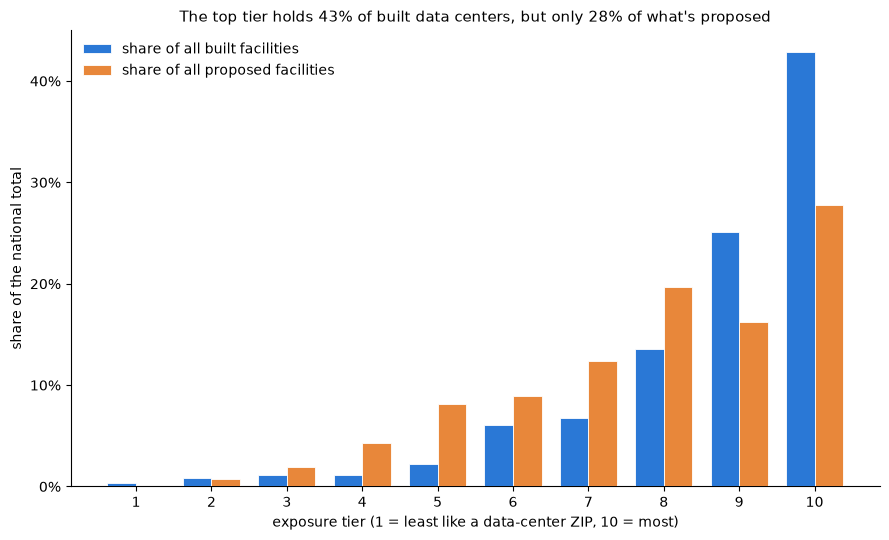

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
x = tier_shares["tier"].to_numpy()
w = 0.38
ax.bar(x - w/2, tier_shares["built_share"] * 100, width=w, color="#2a78d6",
       edgecolor="white", linewidth=0.6, zorder=3, label="share of all built facilities")
ax.bar(x + w/2, tier_shares["pipeline_share"] * 100, width=w, color="#e8873a",
       edgecolor="white", linewidth=0.6, zorder=3, label="share of all proposed facilities")
ax.set_xticks(x)
ax.set_xlabel("exposure tier (1 = least like a data-center ZIP, 10 = most)")
ax.set_ylabel("share of the national total")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("The top tier holds 43% of built data centers, but only 28% of what's proposed", fontsize=11)
ax.legend(frameon=False, loc="upper left")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_risk_divide_tiers.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 2: the 206 new-frontier ZIPs skew rural, more than the ZIPs already hosting

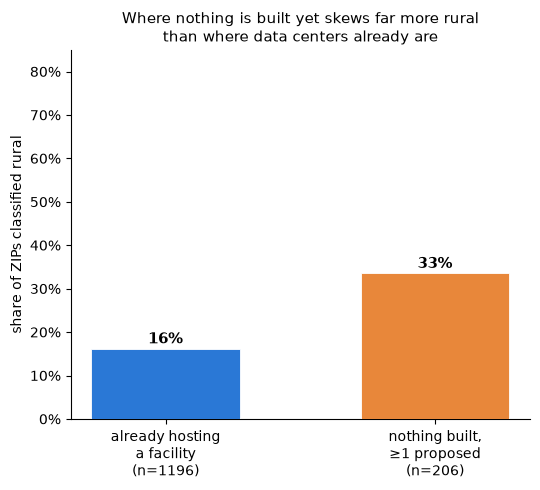

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
labels = ["already hosting\na facility\n(n=%d)" % hosting.sum(),
          "nothing built,\n\u22651 proposed\n(n=%d)" % div.sum()]
vals = [host_rural * 100, div_rural * 100]
colors = ["#2a78d6", "#e8873a"]
bars = ax.bar(labels, vals, color=colors, edgecolor="white", linewidth=0.6, width=0.55, zorder=3)
for b, v in zip(bars, vals):
    ax.annotate(f"{v:.0f}%", (b.get_x() + b.get_width()/2, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_ylabel("share of ZIPs classified rural")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_ylim(0, 85)
ax.set_title("Where nothing is built yet skews far more rural\nthan where data centers already are", fontsize=11)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_risk_divide_rural.png", dpi=150, bbox_inches="tight")
plt.show()